In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
uni2_results = '/fast/AG_Kainmueller/nkoreub/Pathology-Foundation-Model-Benchmark/experiments/unetr_uni2_1610_1101_pathocell2_3658092/train/test_results/test_metrics_best_model.csv'
hovernext_results = '/fast/AG_Kainmueller/nkoreub/Pathology-Foundation-Model-Benchmark/experiments/hovernext_lizard_clweight_convnextv2_large.fcmae_ft_in22k_in1k_1610_1346_pathocell2_3663596/train/test_results/test_metrics_best_model.csv'

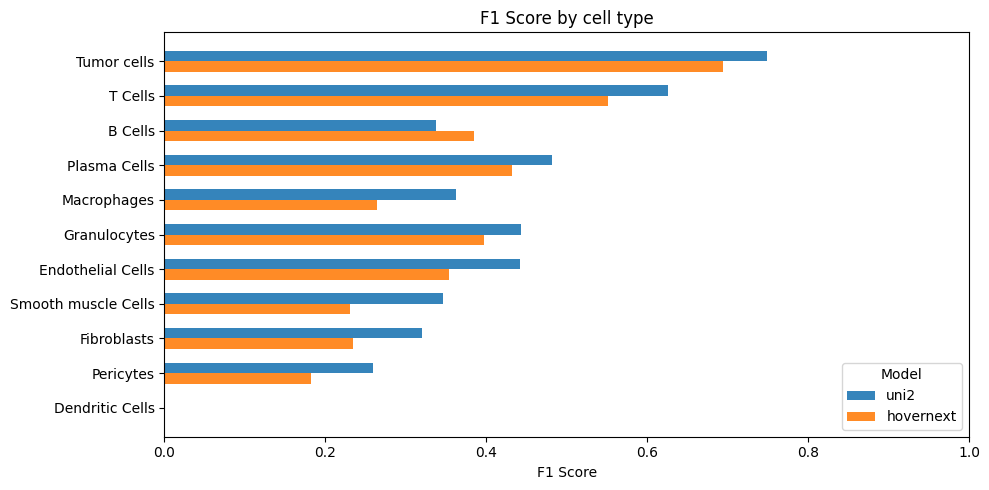

In [3]:

metric_name = "f1_score"  # change to "precision", "recall", or "accuracy" if needed

model_files = {
    "uni2": uni2_results,
    "hovernext": hovernext_results,
}

def load_per_class_scores(csv_path, metric):
    row = pd.read_csv(csv_path).iloc[0]
    scores = {}
    for column, value in row.items():
        if "/" not in column:
            continue
        cell_type, column_metric = column.rsplit("/", 1)
        if column_metric == metric:
            scores[cell_type] = value
    return pd.Series(scores)

scores = pd.concat(
    [load_per_class_scores(path, metric_name).rename(model) for model, path in model_files.items()],
    axis=1,
    join="inner",
)

cell_order = [
    "Tumor cells",
    "T Cells",
    "B Cells",
    "Plasma Cells",
    "Macrophages",
    "Granulocytes",
    "Endothelial Cells",
    "Smooth muscle Cells",
    "Fibroblasts",
    "Pericytes",
    "Dendritic Cells",
]

scores = scores.reindex([cell for cell in cell_order if cell in scores.index])

n_cell_types = len(scores.index)
n_models = len(scores.columns)
bar_height = 0.35
group_spacing = 0.45
group_positions = np.arange(n_cell_types) * (n_models * bar_height + group_spacing)

fig_height = max(5, 0.45 * n_cell_types)
fig, ax = plt.subplots(figsize=(10, fig_height))

colors = {"uni2": "#1f77b4", "hovernext": "#ff7f0e"}

for i, model in enumerate(scores.columns):
    offset = (i - (n_models - 1) / 2) * bar_height
    ax.barh(
        group_positions + offset,
        scores[model].values,
        height=bar_height,
        label=model,
        color=colors.get(model),
        alpha=0.9,
    )

ax.set_yticks(group_positions)
ax.set_yticklabels(scores.index)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel(metric_name.replace("_", " ").title())
ax.set_title(f"{metric_name.replace('_', ' ').title()} by cell type")
ax.grid(False)
ax.legend(title="Model", loc="lower right")
plt.tight_layout()
plt.show()

In [1]:
uni2_predictions = '/fast/AG_Kainmueller/nkoreub/Pathology-Foundation-Model-Benchmark/experiments/unetr_uni2_1610_1101_pathocell2_3658092/train/test_results/predictions.csv'
hovernext_predictions = '/fast/AG_Kainmueller/nkoreub/Pathology-Foundation-Model-Benchmark/experiments/hovernext_lizard_clweight_convnextv2_large.fcmae_ft_in22k_in1k_1610_1346_pathocell2_3663596/train/test_results/predictions.csv'

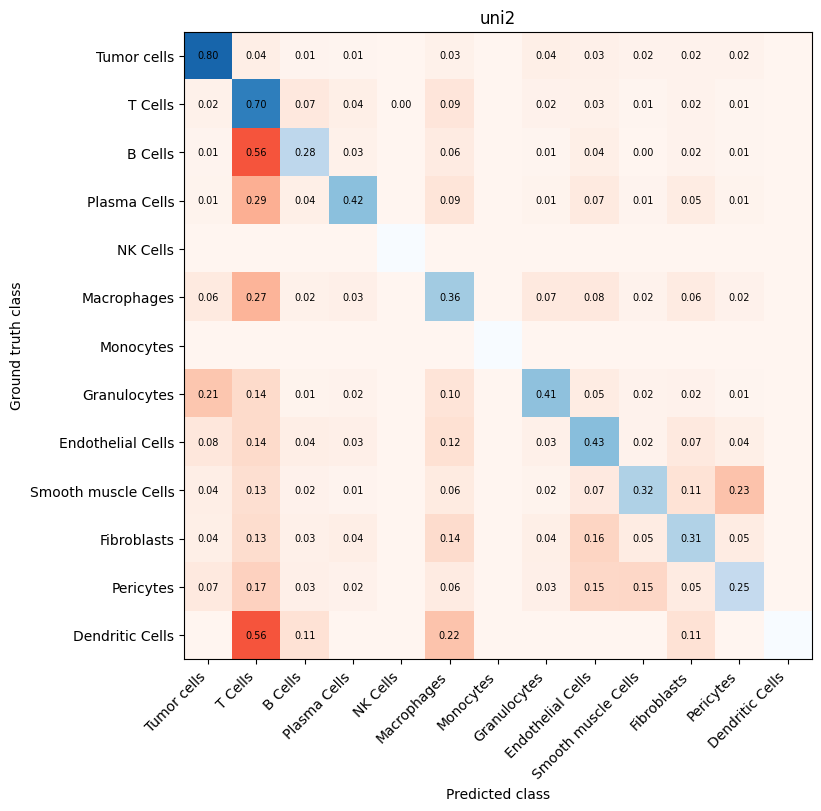

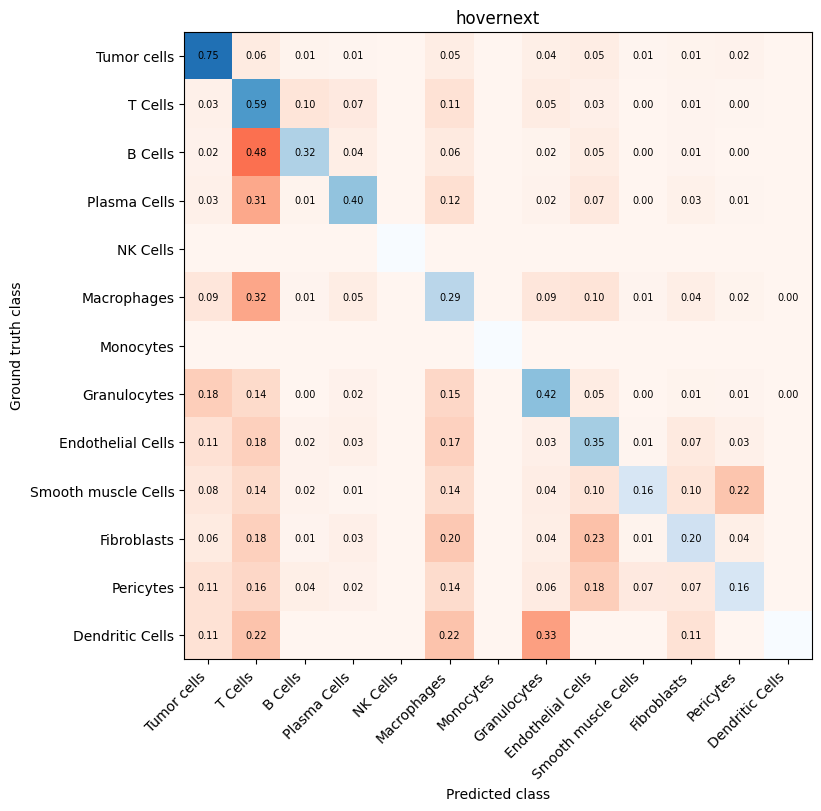

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

class_names = [
    "Tumor cells",
    "T Cells",
    "B Cells",
    "Plasma Cells",
    "NK Cells",
    "Macrophages",
    "Monocytes",
    "Granulocytes",
    "Endothelial Cells",
    "Smooth muscle Cells",
    "Fibroblasts",
    "Pericytes",
    "Dendritic Cells",
]

label_to_name = {idx + 1: name for idx, name in enumerate(class_names)}
model_files = {
    "uni2": uni2_predictions,
    "hovernext": hovernext_predictions,
}

def build_confusion_matrix(csv_path):
    df = pd.read_csv(csv_path)
    df = df[df["groundtruth"].isin(label_to_name)]
    df = df[df["pred_class_name"].isin(class_names)]

    y_true = df["groundtruth"].map(label_to_name)
    y_pred = df["pred_class_name"]

    cm = pd.crosstab(
        pd.Categorical(y_true, categories=class_names, ordered=True),
        pd.Categorical(y_pred, categories=class_names, ordered=True),
        dropna=False,
    ).reindex(index=class_names, columns=class_names, fill_value=0)

    row_totals = cm.sum(axis=1).replace(0, np.nan)
    return cm.div(row_totals, axis=0).fillna(0)

for model_name, csv_path in model_files.items():
    cm_pct = build_confusion_matrix(csv_path)
    matrix = cm_pct.values
    diagonal_mask = np.eye(matrix.shape[0], dtype=bool)
    off_diagonal_mask = ~diagonal_mask

    fig, ax = plt.subplots(figsize=(10, 8), constrained_layout=True)
    ax.set_title(model_name)
    ax.set_xticks(np.arange(len(class_names)))
    ax.set_yticks(np.arange(len(class_names)))
    ax.set_xticklabels(class_names, rotation=45, ha="right")
    ax.set_yticklabels(class_names)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Ground truth class")

    blue_cmap = plt.cm.Blues.copy()
    red_cmap = plt.cm.Reds.copy()
    blue_cmap.set_bad(alpha=0)
    red_cmap.set_bad(alpha=0)

    off_diagonal_data = np.ma.array(matrix, mask=~off_diagonal_mask)
    diagonal_data = np.ma.array(matrix, mask=~diagonal_mask)

    ax.imshow(off_diagonal_data, cmap=red_cmap, vmin=0, vmax=1)
    ax.imshow(diagonal_data, cmap=blue_cmap, vmin=0, vmax=1)

    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            value = matrix[i, j]
            if value > 0:
                ax.text(j, i, f"{value:.2f}", ha="center", va="center", color="black", fontsize=7)

    plt.show()